# MSA com aplicações em Python

**Ruan Carvalho Mayworm · Versão 1.0 · 10/11/2026**

[Diretório no GitHub](https://github.com/rcmayworm/rcmayworm.github.io/tree/main/notebooks/msa) · [Abrir no Colab](https://colab.research.google.com/github/rcmayworm/rcmayworm.github.io/blob/main/notebooks/msa/v1.0/msa_aplicacoes.ipynb)

Os exemplos acompanham o e-book *MSA — Análise de Sistemas de Medição*. A execução é opcional. Os dados são hipotéticos ou simulados.

## Como começar

1. No Colab, entre com sua conta Google e salve uma cópia no Drive pelo menu Arquivo.
2. Conecte ao ambiente de execução e execute as quatro células de preparação, na ordem.
3. Execute as células dos capítulos com o botão de reprodução ou Shift+Enter.
4. Depois de alterar os dados, execute novamente o cálculo e seu gráfico.

O Colab fornece um ambiente Python remoto acessível pelo navegador. O notebook contém os dados, as funções e as figuras em um único arquivo. As funções próprias do livro estão definidas nas células de preparação abaixo. Python 3.13, NumPy 2.2.6, SciPy 1.15.3 e Matplotlib 3.10.9 foram usados na verificação.

## Preparação 1 · Bibliotecas e aparência das figuras

NumPy trabalha com os vetores e matrizes. SciPy fornece as rotinas estatísticas. Matplotlib desenha as figuras. A função configurar_estilo_grafico() define a aparência.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats as estatistica
from itertools import product as produto
from IPython.display import display

"""
Módulo de estilo visual padrão para figuras da série "eBook — Metrologia Descomplicada".
Configurado para layout de página inteira (Classe book, A4 com margens de 2,5 cm).
Largura útil do texto: 160 mm (~6,3 polegadas).
Exportação simultânea em formato vetorial (.pdf) e alta resolução (.png 300 dpi).
"""

import matplotlib.pyplot as plt

# Paleta oficial (sincronizada com o preâmbulo LaTeX)
AZUL_METROLOGIA = "#0F4C81"   # RGB(15, 76, 129) - Cor primária técnica
VERDE_DICA = "#2E8B57"        # RGB(46, 139, 87) - Conformidade e boas práticas
VERMELHO_ALERTA = "#B22222"   # RGB(178, 34, 34) - Limites, rejeição e alertas
LARANJA_DESTAQUE = "#D97706"  # Avisos estatísticos e limites intermediários
CINZA_TEXTO = "#2D3748"       # Eixos, rótulos e anotações
CINZA_GRADE = "#E2E8F0"       # Linhas de grade suaves
FUNDO_SUAVE_AZUL = "#EBF4FA"
FUNDO_SUAVE_VERDE = "#EAF5EE"
FUNDO_SUAVE_VERMELHO = "#FBEAEA"

# Dimensões padrão calibradas para largura útil do livro (160 mm = 6,3 pol)
LARGURA_UTIL_POL = 6.3
DIMENSAO_PADRAO = (6.3, 3.6)       # Proporção 16:9 clássica para página inteira
DIMENSAO_PAINEL_DUPLO = (6.3, 3.2)  # Para 2 subplots lado a lado (1x2)
DIMENSAO_PAINEL_TRIPLO = (6.3, 2.7) # Para 3 subplots lado a lado (1x3)
DIMENSAO_COMPACTA = (5.0, 3.2)      # Para gráficos centrados menores


def configurar_estilo_grafico() -> None:
    """Configura o Matplotlib com tipografia limpa, vetorial e proporções harmônicas com o LaTeX."""
    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["DejaVu Sans", "Arial", "Helvetica", "Calibri"],
        "font.size": 9.5,
        "axes.titlesize": 10.5,
        "axes.titleweight": "bold",
        "axes.labelsize": 9.5,
        "axes.edgecolor": CINZA_TEXTO,
        "axes.linewidth": 0.8,
        "xtick.labelsize": 8.5,
        "ytick.labelsize": 8.5,
        "xtick.color": CINZA_TEXTO,
        "ytick.color": CINZA_TEXTO,
        "text.color": CINZA_TEXTO,
        "legend.fontsize": 8.5,
        "legend.frameon": False,
        "figure.dpi": 150,
        "savefig.dpi": 300,
        "savefig.bbox": "tight",
        "savefig.pad_inches": 0.08,
        "pdf.fonttype": 42,  # Fontes TrueType preservadas no PDF vetorial
        "ps.fonttype": 42,
    })

## Preparação 2 · Dados dos eixos usinados

A matriz tem as dimensões peça × avaliador × repetição. As 90 leituras são didáticas e estão em milímetros.

In [2]:
"""
Conjunto de dados oficial do Exemplo Longitudinal Principal do eBook MSA:
Medição do diâmetro externo de 10 eixos usinados (nominal 25,000 +/- 0,050 mm, T = 0,100 mm)
por 3 avaliadores (A, B, C) com 3 repetições cada (N = 90 leituras), usando micrômetro digital
com resolução de 0,001 mm.
"""

import numpy as np

NOMINAL_MM = 25.000
LIE_MM = 24.950
LSE_MM = 25.050
TOLERANCIA_MM = LSE_MM - LIE_MM  # 0.100 mm
RESOLUCAO_MM = 0.001

# Dimensões: (10 peças, 3 avaliadores [A, B, C], 3 repetições [r1, r2, r3])
DADOS_EIXOS_MM = np.array([
    # Peça 1
    [[24.968, 24.970, 24.969], [24.971, 24.973, 24.972], [24.967, 24.970, 24.967]],
    # Peça 2
    [[24.982, 24.985, 24.982], [24.986, 24.988, 24.987], [24.981, 24.983, 24.982]],
    # Peça 3
    [[24.991, 24.993, 24.992], [24.994, 24.997, 24.994], [24.989, 24.992, 24.989]],
    # Peça 4
    [[24.998, 25.002, 25.000], [25.002, 25.004, 25.003], [24.997, 24.999, 24.998]],
    # Peça 5
    [[25.004, 25.006, 25.005], [25.007, 25.010, 25.007], [25.002, 25.005, 25.002]],
    # Peça 6
    [[25.009, 25.012, 25.009], [25.013, 25.015, 25.014], [25.008, 25.010, 25.009]],
    # Peça 7
    [[25.015, 25.017, 25.016], [25.018, 25.021, 25.018], [25.013, 25.016, 25.013]],
    # Peça 8
    [[25.021, 25.025, 25.023], [25.025, 25.027, 25.026], [25.020, 25.022, 25.021]],
    # Peça 9
    [[25.029, 25.031, 25.030], [25.032, 25.035, 25.032], [25.027, 25.030, 25.027]],
    # Peça 10
    [[25.037, 25.040, 25.037], [25.041, 25.043, 25.042], [25.036, 25.038, 25.037]],
])


## Preparação 3 · Dados e funções de cálculo do livro

Aqui estão as definições de plano_coleta(), medias_amplitudes(), anova_cruzada(), indicadores_grr(), ajustar_tendencia(), carta_medias_amplitudes(), matriz_classificacao(), kappa_cohen(), kappa_fleiss() e dados_resistencia(), além dos conjuntos didáticos dos capítulos 8, 9, 10 e 13.

In [3]:
"""Dados e cálculos reproduzíveis para o e-book de MSA."""
from itertools import product as produto

import numpy as np
from scipy import stats as estatistica


EIXOS_MM = DADOS_EIXOS_MM
TOLERANCIA_EIXOS_MM = TOLERANCIA_MM

# Constantes do exemplo do livro: 10 peças, 3 avaliadores e 3 repetições.
CONSTANTES_MA = (0.5908, 0.5231, 0.3146)


def plano_coleta(n_pecas, n_avaliadores, n_repeticoes, semente=42):
    """Sorteia a ordem das peças dentro de cada avaliador e rodada."""
    gerador = np.random.default_rng(semente)
    return [
        (int(peca), avaliador, rodada)
        for rodada, avaliador in produto(range(n_repeticoes), range(n_avaliadores))
        for peca in gerador.permutation(n_pecas)
    ]


def medias_amplitudes(leituras, constantes):
    """Aplica as constantes especificadas para um delineamento cruzado balanceado."""
    n_pecas, _, n_repeticoes = leituras.shape
    k1, k2, k3 = constantes
    # O último eixo contém as repetições de uma mesma célula.
    amplitudes = np.ptp(leituras, axis=2)
    amplitude_avaliadores = np.ptp(leituras.mean(axis=(0, 2)))
    amplitude_pecas = np.ptp(leituras.mean(axis=(1, 2)))
    ev = amplitudes.mean() * k1
    variancia_av = (amplitude_avaliadores * k2)**2 - ev**2 / (n_pecas * n_repeticoes)
    pv = amplitude_pecas * k3
    return ev, np.sqrt(max(0, variancia_av)), pv


def anova_cruzada(leituras, *, alfa_agrupamento=None):
    """Estima um modelo cruzado balanceado de efeitos aleatórios por momentos.

    Ordem das linhas: peça, avaliador, interação e repetibilidade.
    Ordem das variâncias: repetibilidade, avaliador, interação e peça.
    """
    n_pecas, n_avaliadores, n_repeticoes = leituras.shape
    # Centrar preserva as somas de quadrados e melhora a precisão numérica.
    y = leituras - leituras.mean()
    peca = y.mean(axis=(1, 2))
    avaliador = y.mean(axis=(0, 2))
    celula = y.mean(axis=2)
    interacao = celula - peca[:, None] - avaliador[None, :]
    sq = np.array([
        n_avaliadores * n_repeticoes * np.sum(peca**2),
        n_pecas * n_repeticoes * np.sum(avaliador**2),
        n_repeticoes * np.sum(interacao**2),
        np.sum((y - celula[:, :, None])**2),
    ])
    gl = np.array([
        n_pecas - 1,
        n_avaliadores - 1,
        (n_pecas - 1) * (n_avaliadores - 1),
        n_pecas * n_avaliadores * (n_repeticoes - 1),
    ])
    qm = sq / gl
    if qm[3] == 0:
        raise ValueError("O teste F requer quadrado médio residual positivo.")
    f_interacao = qm[2] / qm[3]
    p_interacao = estatistica.f.sf(f_interacao, gl[2], gl[3])
    agrupou = alfa_agrupamento is not None and p_interacao > alfa_agrupamento
    residuo = sq[2:].sum() / gl[2:].sum() if agrupou else qm[3]
    denominador = residuo if agrupou else qm[2]
    variancias_brutas = np.array([
        residuo,
        (qm[1] - denominador) / (n_pecas * n_repeticoes),
        0 if agrupou else (qm[2] - qm[3]) / n_repeticoes,
        (qm[0] - denominador) / (n_avaliadores * n_repeticoes),
    ])
    # Preserva as estimativas brutas e usa zero como limite físico.
    return sq, gl, qm, p_interacao, agrupou, variancias_brutas, np.maximum(variancias_brutas, 0)


def indicadores_grr(ev, av, pv, tolerancia):
    """Devolve desvio-padrão, percentuais de estudo, tolerância, contribuição e ndc."""
    grr = np.hypot(ev, av)
    total = np.hypot(grr, pv)
    desvios_padrao = np.array([ev, av, grr, pv, total])
    ndc = max(1, int(1.41 * pv / grr)) if grr > 0 else None
    return np.column_stack([
        desvios_padrao, 100 * desvios_padrao / total, 600 * desvios_padrao / tolerancia, 100 * (desvios_padrao / total)**2
    ]), ndc


def ajustar_tendencia(referencia, leituras):
    """Ajusta a tendência em função da referência usando as leituras individuais."""
    x = np.repeat(referencia, leituras.shape[1])
    tendencia = leituras - referencia[:, None]
    ajuste = estatistica.linregress(x, tendencia.ravel())
    return tendencia.mean(axis=1), ajuste


def carta_medias_amplitudes(leituras, n_fase1, constantes):
    """Calcula os limites da Fase I e sinaliza pontos além desses limites."""
    a2, d3, d4 = constantes
    medias = leituras.mean(axis=1)
    amplitudes = np.ptp(leituras, axis=1)
    centro = medias[:n_fase1].mean()
    amplitude_media = amplitudes[:n_fase1].mean()
    limites_x = np.array([centro - a2 * amplitude_media, centro + a2 * amplitude_media])
    limites_r = amplitude_media * np.array([d3, d4])
    sinais_x = np.flatnonzero((medias < limites_x[0]) | (medias > limites_x[1])) + 1
    sinais_r = np.flatnonzero((amplitudes < limites_r[0]) | (amplitudes > limites_r[1])) + 1
    return medias, amplitudes, limites_x, limites_r, sinais_x, sinais_r


def matriz_classificacao(referencia, decisao):
    """Usa linhas de referência e colunas de decisão, na ordem NOK, OK."""
    contagens = np.zeros((2, 2), dtype=int)
    np.add.at(contagens, (referencia, decisao), 1)
    return contagens


def kappa_cohen(contagens):
    """Calcula o kappa de Cohen a partir da matriz de classificação 2 × 2."""
    n = contagens.sum()
    observada = contagens.trace() / n
    esperada = contagens.sum(axis=0) @ contagens.sum(axis=1) / n**2
    return (observada - esperada) / (1 - esperada) if esperada < 1 else np.nan


def kappa_fleiss(decisoes):
    """Calcula o kappa de Fleiss em uma rodada, com uma linha por peça."""
    n_avaliadores = decisoes.shape[1]
    ok = decisoes.sum(axis=1)
    contagens = np.column_stack([n_avaliadores - ok, ok])
    observada = (contagens * (contagens - 1)).sum(axis=1).mean()
    observada /= n_avaliadores * (n_avaliadores - 1)
    esperada = np.sum((contagens.mean(axis=0) / n_avaliadores)**2)
    return (observada - esperada) / (1 - esperada) if esperada < 1 else np.nan


# Cap. 8: 60 leituras sintéticas, em passos de 1 micrômetro.
REFERENCIAS_LINEARIDADE_MM = np.arange(20, 101, 20)
TENDENCIAS_LINEARIDADE_MM = np.array([-4, -1, 2, 5, 8]) / 1000
LEITURAS_LINEARIDADE_MM = REFERENCIAS_LINEARIDADE_MM[:, None] + TENDENCIAS_LINEARIDADE_MM[:, None]
LEITURAS_LINEARIDADE_MM = LEITURAS_LINEARIDADE_MM + np.tile([-1, 0, 1, 0], 3) / 1000

# Cap. 9: subgrupos sintéticos que reproduzem os resumos do livro.
MEDIAS_DIARIAS_EIXOS_MM = 25 + np.array([
    3, 8, -3, 11, -1, 6, 0, 7, 5, -2, 10, 2, 9, -4, 6, 1, 12, 4, -1, 7,
    6, 9, 24, 4,
]) / 10000
AMPLITUDES_DIARIAS_EIXOS_MM = np.r_[np.tile([26, 30], 10), [28, 30, 26, 28]] / 10000
LEITURAS_DIARIAS_EIXOS_MM = (
    MEDIAS_DIARIAS_EIXOS_MM[:, None]
    + np.round(AMPLITUDES_DIARIAS_EIXOS_MM[:, None] * np.array([-0.5, -0.25, 0, 0.25, 0.5]), 4)
)

# Cap. 10: matrizes fornecidas no manuscrito, na ordem NOK, OK.
MATRIZES_TAMPAS = np.array([[[45, 0], [3, 102]], [[43, 2], [5, 100]],
                         [[41, 4], [8, 97]]])


def dados_resistencia():
    """Gera os três conjuntos sintéticos independentes, em miliohms."""
    gerador = np.random.default_rng(42)
    peca = np.array([0.61, 0.65, 0.69, 0.73, 0.78, 0.83, 0.87, 0.91, 0.95, 0.98])
    avaliador = np.array([0, 0.012, -0.006])
    # O contato do operador B depende da geometria do terminal.
    interacao = np.outer(np.linspace(-1, 1, 10), [0.0, 0.032, 0.0])
    modelo = peca[:, None] + avaliador + interacao
    cruzado = np.round(modelo[:, :, None] + gerador.normal(0, 0.006, (10, 3, 3)), 3)

    referencias = np.array([0.60, 0.70, 0.80, 0.90, 1.00])
    tendencia = 0.004 + 0.05 * (referencias - 0.80)
    linearidade = np.round(
        referencias[:, None] + tendencia[:, None] + gerador.normal(0, 0.002, (5, 6)), 3
    )

    # Fase I em torno de 0,804 mOhm, com um salto hipotético no dia 23.
    medias_diarias = np.r_[np.tile([0.802, 0.803, 0.805, 0.806, 0.804], 4),
                         [0.804, 0.805, 0.815, 0.804]]
    diarias = medias_diarias[:, None] + np.array([-0.004, -0.002, 0, 0.002, 0.004])
    return cruzado, referencias, linearidade, diarias


# Cap. 13: cada caractere representa um terminal, sempre na mesma ordem.
# 0 = NOK; 1 = OK. Pares de strings representam as rodadas cegas 1 e 2.
TEXTO_REFERENCIA_CRIMPAGEM = "000000000000111111111111"
RODADAS_CRIMPAGEM = (
    ("000000000010111111111111", "000000000010111111111101"),
    ("000000000111111111111111", "000000001011111111111111"),
    ("000000000000111111111101", "000000000000011111111101"),
)
DECISOES_CRIMPAGEM = np.array([[list(rodada) for rodada in avaliador]
                            for avaliador in RODADAS_CRIMPAGEM], dtype=int).transpose(2, 0, 1)
REFERENCIA_CRIMPAGEM = np.array(list(TEXTO_REFERENCIA_CRIMPAGEM), dtype=int)

## Preparação 4 · Funções de visualização do livro

Estas funções preparam o intervalo de confiança e desenham as cartas, os perfis de interação e as matrizes de classificação a partir dos resultados dos cálculos.

In [4]:
"""Rotinas de visualização utilizadas nas aplicações do e-book."""
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats as estatistica


AZUL = "#0F4C81"
VERDE = "#2E8B57"
VERMELHO = "#B22222"


def dados_grafico_tendencia(referencia, leituras, ajuste):
    """Prepara a reta e o intervalo pontual de 95% para a média ajustada."""
    referencias = np.repeat(referencia, leituras.shape[1])
    desvios = (leituras - referencia[:, None]).ravel()
    malha = np.linspace(referencia.min(), referencia.max(), 100)
    reta = ajuste.intercept + ajuste.slope * malha
    n = len(referencias)

    # O resíduo mede a distância vertical entre cada ponto e a reta.
    residuos = desvios - ajuste.intercept - ajuste.slope * referencias
    desvio_residual = np.linalg.norm(residuos) / np.sqrt(n - 2)
    soma_quadrados_x = np.sum((referencias - referencias.mean())**2)
    erro_padrao = desvio_residual * np.sqrt(
        1/n + (malha - referencias.mean())**2 / soma_quadrados_x
    )
    semi_largura = estatistica.t.ppf(0.975, n - 2) * erro_padrao
    return referencias, desvios, malha, reta, semi_largura


def grafico_estabilidade(
    medias, amplitudes, limites_x, limites_r, sinais_x, sinais_r,
    *, dias_fase1, unidade,
):
    """Desenha as duas cartas a partir dos resultados já calculados."""
    configurar_estilo_grafico()
    figura, eixos = plt.subplots(2, 1, sharex=True, figsize=(6.8, 4.2))
    dias = np.arange(1, len(medias) + 1)
    for eixo, valores, limites, sinais, rotulo in zip(
        eixos, (medias, amplitudes), (limites_x, limites_r),
        (sinais_x, sinais_r), ("Média", "Amplitude")
    ):
        # Os dias são numerados a partir de 1. O índice do array começa em 0.
        eixo.plot(dias, valores, "o-", color=AZUL, ms=3)
        eixo.scatter(sinais, valores[sinais - 1], color=VERMELHO, zorder=3)

        # As linhas horizontais mostram o centro e os limites da Fase I.
        eixo.axhline(valores[:dias_fase1].mean(), color=VERDE, lw=1)
        for limite in limites:
            eixo.axhline(limite, color=VERMELHO, ls="--", lw=1)
        eixo.axvline(dias_fase1 + 0.5, color="0.55", ls=":")
        eixo.set_ylabel(f"{rotulo} ({unidade})")
        eixo.ticklabel_format(style="plain", useOffset=False, axis="y")
    eixos[-1].set_xlabel("Dia")
    figura.tight_layout()
    return figura


def grafico_interacao(leituras):
    """Mostra os perfis dos avaliadores e o contraste B menos A."""
    configurar_estilo_grafico()
    figura, (eixo_perfis, eixo_contraste) = plt.subplots(
        2, 1, sharex=True, figsize=(6.8, 4.6)
    )
    terminais = np.arange(1, len(leituras) + 1)
    medias = leituras.mean(axis=2)

    # A transposição põe a série de cada avaliador em uma linha.
    for rotulo, cor, serie in zip("ABC", (AZUL, VERMELHO, VERDE), medias.T):
        eixo_perfis.plot(terminais, serie, "o-", color=cor, label=rotulo)
    eixo_perfis.set_ylabel("Média (mΩ)")
    eixo_perfis.legend(title="Operador")

    contraste = medias[:, 1] - medias[:, 0]
    eixo_contraste.plot(terminais, contraste, "o-", color=VERMELHO)
    eixo_contraste.axhline(0, color="0.55", ls=":")
    eixo_contraste.set(xlabel="Terminal", ylabel="B − A (mΩ)", xticks=terminais)
    figura.tight_layout()
    return figura


def grafico_crimpagem(referencia, decisoes):
    """Apresenta as matrizes de uma rodada com a mesma escala de cor."""
    configurar_estilo_grafico()
    figura, eixos = plt.subplots(1, 3, figsize=(6.8, 2.7), sharey=True)
    contagem_maxima = np.bincount(referencia).max()

    for eixo, avaliador, decisao in zip(eixos, "ABC", decisoes.T):
        matriz = matriz_classificacao(referencia, decisao)
        eixo.imshow(matriz, cmap="Blues", vmin=0, vmax=contagem_maxima)
        # O valor escrito preserva a leitura exata, além da cor.
        for (linha, coluna), contagem in np.ndenumerate(matriz):
            cor = "white" if contagem > 0.6 * contagem_maxima else AZUL
            eixo.text(coluna, linha, str(contagem), ha="center",
                      va="center", color=cor)
        eixo.set(title=f"Avaliador {avaliador}", xticks=[0, 1], yticks=[0, 1])
        eixo.set_xticklabels(["NOK", "OK"])
        eixo.set_yticklabels(["NOK", "OK"])
        eixo.set_xlabel("Decisão")
    eixos[0].set_ylabel("Referência")
    figura.tight_layout()
    return figura

## Cap. 1: variação observada

In [5]:
# array() cria um vetor NumPy. Cada posição representa uma peça.
desvios_pecas_um = np.array([-6, -2, 2, 6])
erros_medicao_um = np.array([-1, 1, 1, -1])
observados_um = desvios_pecas_um + erros_medicao_um

# cov() calcula covariâncias. [0, 1] seleciona a covariância cruzada.
# ddof=1 usa n−1 no denominador, também em var(), a variância.
covariancia = np.cov(desvios_pecas_um, erros_medicao_um, ddof=1)[0, 1]
series_um = (desvios_pecas_um, erros_medicao_um, observados_um)
variancias = [np.var(serie_um, ddof=1) for serie_um in series_um]
print(f"Covariância: {covariancia:.2f} µm²")
print("Variâncias (peça, erro, observada) em µm²:")
print(", ".join(f"{variancia:.2f}" for variancia in variancias))

Covariância: 0.00 µm²
Variâncias (peça, erro, observada) em µm²:
26.67, 1.33, 28.00


## Cap. 2: repetibilidade e tendência

In [6]:
# Cinco leituras em milímetros de uma mesma referência.
referencia_mm = 25.000
leituras_mm = np.array([24.999, 25.000, 25.001, 25.001, 25.002])

# mean() calcula a média. A tendência é a média menos a referência.
tendencia_mm = leituras_mm.mean() - referencia_mm

# ddof=1 calcula o desvio-padrão amostral.
desvio_mm = leituras_mm.std(ddof=1)

# Multiplicar por 1000 converte mm para µm. .2f mostra duas casas.
print(f"Tendência: {1000 * tendencia_mm:+.2f} µm")
print(f"Desvio-padrão: {1000 * desvio_mm:.2f} µm")

Tendência: +0.60 µm
Desvio-padrão: 1.14 µm


## Cap. 3: plano e conferência

In [7]:
# shape informa quantas peças, avaliadores e rodadas há na matriz.
ordem_coleta = plano_coleta(*EIXOS_MM.shape)
chaves = np.array(ordem_coleta)

# len() conta itens. set() mantém as combinações distintas.
# assert verifica se a condição é verdadeira.
assert len(ordem_coleta) == len(set(ordem_coleta)) == EIXOS_MM.size

# isfinite() testa cada valor. all() exige que todos sejam finitos.
assert np.isfinite(EIXOS_MM[tuple(chaves.T)]).all()
print(f"{len(ordem_coleta)} leituras válidas")
print(f"{len(set(ordem_coleta))} combinações distintas")

90 leituras válidas
90 combinações distintas


## Cap. 4: médias por peça e avaliador

In [8]:
# mean() calcula a média. axis=2 seleciona o eixo das repetições.
medias_celulas_mm = EIXOS_MM.mean(axis=2)

# As colunas 1 e 2 correspondem a B e C. Compare peça por peça.
diferenca_bc_um = 1000 * (medias_celulas_mm[:, 1]
                          - medias_celulas_mm[:, 2])
print(f"Menor diferença B − C: {diferenca_bc_um.min():.2f} µm")
print(f"Maior diferença B − C: {diferenca_bc_um.max():.2f} µm")

Menor diferença B − C: 4.00 µm
Maior diferença B − C: 5.00 µm


## Cap. 5: médias e amplitudes

In [9]:
# [0, 0] seleciona as três leituras da peça 1 com o avaliador A.
leituras_peca1_a_mm = EIXOS_MM[0, 0]
media_peca1_a_mm = leituras_peca1_a_mm.mean()

# ptp() calcula máximo menos mínimo nas repetições de cada célula.
amplitudes_mm = np.ptp(EIXOS_MM, axis=2)
print(f"Média da célula 1/A: {media_peca1_a_mm:.3f} mm")
print(f"Amplitude da célula 1/A: {amplitudes_mm[0, 0]:.3f} mm")
print(f"Amplitude média global: {amplitudes_mm.mean():.6f} mm")

# Aplicar as constantes do delineamento de 10 × 3 × 3.
ev, av, pv = medias_amplitudes(EIXOS_MM, CONSTANTES_MA)
resultado_ma, ndc_ma = indicadores_grr(ev, av, pv, TOLERANCIA_EIXOS_MM)
print(f"Gage R&R: {1000 * resultado_ma[2, 0]:.3f} µm")
print(f"Categorias distintas: {ndc_ma}")

Média da célula 1/A: 24.969 mm
Amplitude da célula 1/A: 0.002 mm
Amplitude média global: 0.002533 mm
Gage R&R: 2.956 µm
Categorias distintas: 10


## Cap. 6: ANOVA cruzada dos eixos

In [10]:
# SQ, GL e QM descrevem a tabela do modelo com interação.
# Para este exemplo, a função agrupa a interação se p > 0,25.
sq, gl, qm, p_interacao, agrupou, _, variancias = anova_cruzada(
    EIXOS_MM, alfa_agrupamento=0.25
)
print("Fonte             GL          SQ          QM")
fontes = ("Peça", "Avaliador", "Interação", "Erro")
# zip() percorre as quatro sequências em conjunto.
for fonte, graus, soma, quadrado in zip(fontes, gl, sq, qm):
    print(f"{fonte:16s} {graus:3d}  {soma:.8f}  {quadrado:.8f}")
print(f"p da interação: {p_interacao:.6f}")
print(f"Interação agrupada: {'sim' if agrupou else 'não'}")

# sqrt() tira a raiz quadrada. sum() soma os componentes de variância.
ev_anova = np.sqrt(variancias[0])
av_anova = np.sqrt(variancias[1:3].sum())
pv_anova = np.sqrt(variancias[3])
resultado_anova, ndc_anova = indicadores_grr(
    ev_anova, av_anova, pv_anova, TOLERANCIA_EIXOS_MM
)

Fonte             GL          SQ          QM
Peça               9  0.03710850  0.00412317
Avaliador          2  0.00037460  0.00018730
Interação         18  0.00000540  0.00000030
Erro              60  0.00012000  0.00000200
p da interação: 0.999973
Interação agrupada: sim


## Cap. 6: gráfico dos componentes

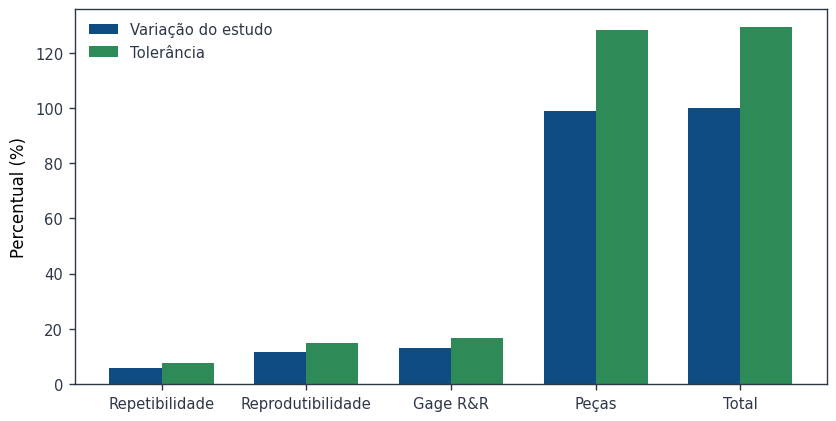

In [11]:
configurar_estilo_grafico()
# subplots() cria a figura e o eixo onde o gráfico será desenhado.
figura_grr, eixo = plt.subplots(figsize=(6.8, 3.5))
componentes = ["Repetibilidade", "Reprodutibilidade",
               "Gage R&R", "Peças", "Total"]
# arange() cria as posições inteiras dos cinco grupos de barras.
posicoes = np.arange(len(componentes))

# A coluna 1 é % do estudo e a 2 é % da tolerância.
# Desloque os centros para que as duas barras fiquem lado a lado.
eixo.bar(posicoes - 0.18, resultado_anova[:, 1], width=0.36,
         color="#0F4C81", label="Variação do estudo")
eixo.bar(posicoes + 0.18, resultado_anova[:, 2], width=0.36,
         color="#2E8B57", label="Tolerância")
# set_xticks() posiciona os rótulos. legend() identifica as séries.
eixo.set_xticks(posicoes, componentes)
eixo.set_ylabel("Percentual (%)")
eixo.legend()
# tight_layout() ajusta os espaços entre os elementos da figura.
figura_grr.tight_layout()

display(figura_grr)

## Cap. 7: denominadores dos índices

In [12]:
# A terceira linha reúne os indicadores do Gage R&R combinado.
desvio_grr_mm, pct_estudo, pct_tolerancia, pct_contribuicao = (
    resultado_anova[2]
)
print(f"Gage R&R: {1000 * desvio_grr_mm:.3f} µm")
print(f"Categorias distintas: {ndc_anova}")
print(f"Variação do estudo: {pct_estudo:.2f}%")
print(f"Tolerância: {pct_tolerancia:.2f}%")
print(f"Contribuição à variância: {pct_contribuicao:.2f}%")

Gage R&R: 2.792 µm
Categorias distintas: 10
Variação do estudo: 12.94%
Tolerância: 16.75%
Contribuição à variância: 1.67%


## Cap. 8: regressão da tendência

In [13]:
# A função subtrai de cada leitura o valor da sua referência.
# O ajuste usa as leituras individuais, mantendo o nível de cada uma.
tendencias_mm, ajuste = ajustar_tendencia(
    REFERENCIAS_LINEARIDADE_MM, LEITURAS_LINEARIDADE_MM
)
tendencias_um = 1000 * tendencias_mm
tendencias_texto = ", ".join(f"{valor:+.1f}" for valor in tendencias_um)

# A regressão da SciPy devolve slope (inclinação) e intercept (intercepto).
variacao_na_faixa_mm = ajuste.slope * np.ptp(REFERENCIAS_LINEARIDADE_MM)
print(f"Tendências por nível: {tendencias_texto} µm")
print(f"Inclinação: {ajuste.slope:.6f} mm/mm")
print(f"Intercepto: {ajuste.intercept:+.6f} mm")
print(f"Variação ajustada na faixa: {variacao_na_faixa_mm:.4f} mm")

Tendências por nível: -4.0, -1.0, +2.0, +5.0, +8.0 µm
Inclinação: 0.000150 mm/mm
Intercepto: -0.007000 mm
Variação ajustada na faixa: 0.0120 mm


## Cap. 8: gráfico da regressão

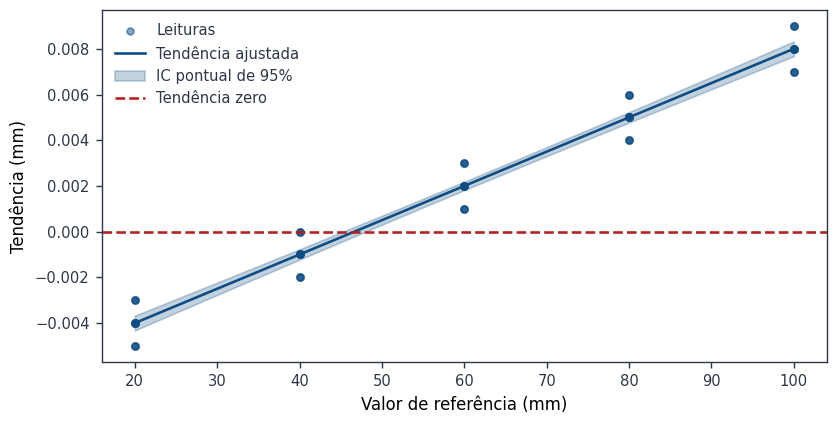

In [14]:
# A malha serve apenas para desenhar a reta e o intervalo.
referencias, desvios, malha, reta, semi_largura = (
    dados_grafico_tendencia(
        REFERENCIAS_LINEARIDADE_MM, LEITURAS_LINEARIDADE_MM, ajuste
    )
)
configurar_estilo_grafico()
figura_tendencia, eixo = plt.subplots(figsize=(6.8, 3.5))

# scatter() mostra as leituras. plot() liga os pontos da reta.
eixo.scatter(referencias, desvios, color="#0F4C81", alpha=0.5,
             s=16, label="Leituras")
eixo.plot(malha, reta, color="#0F4C81", label="Tendência ajustada")
eixo.fill_between(malha, reta - semi_largura, reta + semi_largura,
                  color="#0F4C81", alpha=0.25, label="IC pontual de 95%")
eixo.axhline(0, color="#B22222", ls="--", label="Tendência zero")
eixo.set(xlabel="Valor de referência (mm)", ylabel="Tendência (mm)")
eixo.legend()
figura_tendencia.tight_layout()

display(figura_tendencia)

## Cap. 8: estudo tipo 1

In [15]:
# Uma referência, tolerância de 0,100 mm e fração de 20%.
referencia_mm, tolerancia_mm, fracao = 25.000, 0.100, 0.20

# tile() repete cinco vezes o conjunto de desvios em µm.
leituras_tipo1_mm = referencia_mm + np.tile([1, 2, 3, 2, 2], 5) / 1000
tendencia_tipo1_mm = leituras_tipo1_mm.mean() - referencia_mm
desvio_tipo1_mm = leituras_tipo1_mm.std(ddof=1)

# abs() calcula o módulo. Cgk desconta a magnitude da tendência.
meia_faixa_mm = fracao * tolerancia_mm / 2
cg = fracao * tolerancia_mm / (6 * desvio_tipo1_mm)
cgk = (meia_faixa_mm - abs(tendencia_tipo1_mm)) / (3 * desvio_tipo1_mm)
print(f"Desvio-padrão: {desvio_tipo1_mm:.6f} mm")
print(f"Tendência: {tendencia_tipo1_mm:+.6f} mm")
print(f"Cg: {cg:.2f}")
print(f"Cgk: {cgk:.2f}")

Desvio-padrão: 0.000645 mm
Tendência: +0.002000 mm
Cg: 5.16
Cgk: 4.13


## Cap. 9: cartas de estabilidade

In [16]:
# A2, D3 e D4 correspondem a subgrupos de cinco leituras.
constantes_carta = (0.577, 0.0, 2.114)

# Só os 20 primeiros subgrupos entram na estimativa dos limites.
medias, amplitudes, limites_x, limites_r, sinais_x, sinais_r = (
    carta_medias_amplitudes(LEITURAS_DIARIAS_EIXOS_MM, 20, constantes_carta)
)
print(f"Limites da carta de médias: {limites_x[0]:.5f}, "
      f"{limites_x[1]:.5f} mm")
# tolist() converte o vetor em lista para mostrar os dias no print.
print(f"Dias sinalizados na carta de médias: {sinais_x.tolist()}")
print(f"Limites da carta R: {limites_r[0]:.5f}, {limites_r[1]:.5f} mm")
print(f"Dias sinalizados na carta R: {sinais_r.tolist()}")

Limites da carta de médias: 24.99878, 25.00202 mm
Dias sinalizados na carta de médias: [23]
Limites da carta R: 0.00000, 0.00592 mm
Dias sinalizados na carta R: []


## Cap. 9: gráfico das cartas

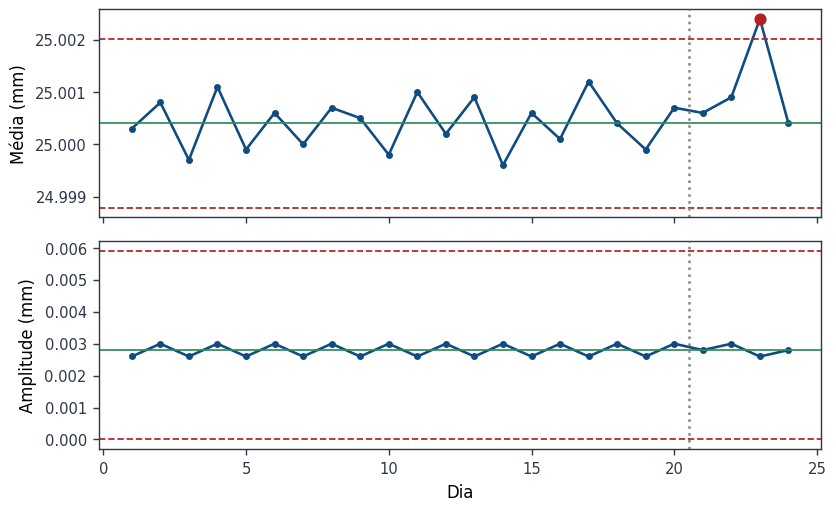

In [17]:
# As duas cartas usam as mesmas datas e limites calculados na Fase I.
# A função usa plot() para os pontos e axhline() para os limites.
figura_estabilidade = grafico_estabilidade(
    medias, amplitudes, limites_x, limites_r, sinais_x, sinais_r,
    dias_fase1=20, unidade="mm"
)

display(figura_estabilidade)

## Cap. 10: comparação com a referência

In [18]:
# Cada matriz tem linhas de referência e colunas de decisão.
# Nos dois eixos, o índice 0 é NOK e o índice 1 é OK.
for avaliador, matriz in zip("ABC", MATRIZES_TAMPAS):
    # Divida cada erro pelo total da classe correspondente.
    taxa_fuga = matriz[0, 1] / matriz[0].sum()
    taxa_falso_alarme = matriz[1, 0] / matriz[1].sum()
    concordancia = kappa_cohen(matriz)
    print(f"{avaliador}: κ={concordancia:.3f}, "
          f"fuga={taxa_fuga:.2%}, falso alarme={taxa_falso_alarme:.2%}")

A: κ=0.953, fuga=0.00%, falso alarme=2.86%
B: κ=0.891, fuga=4.44%, falso alarme=4.76%
C: κ=0.814, fuga=8.89%, falso alarme=7.62%


## Cap. 11: comparar dois balanços

In [19]:
# Divida pela raiz de 3 para as contribuições retangulares do exemplo.
u_tendencia, u_linearidade = np.array([1.20, 0.50]) / np.sqrt(3)

# norm() combina as contribuições independentes em quadratura.
# Os valores já estão em µm. A resolução não é somada outra vez.
u_ms = np.linalg.norm([0.30, 0.45, u_tendencia, u_linearidade])
u_mp = np.linalg.norm([
    0.30, 1.80, u_tendencia, u_linearidade, 2.40, 1.20, 7/np.sqrt(3), 6.20,
])

# Q = 2U/T. Aqui U = 2u e T = 50 µm.
tolerancia_um = 50
print(f"u_MS: {u_ms:.3f} µm | u_MP: {u_mp:.3f} µm")
print(f"Q_MS: {4 * u_ms / tolerancia_um:.2%}")
print(f"Q_MP: {4 * u_mp / tolerancia_um:.2%}")

u_MS: 0.925 µm | u_MP: 8.116 µm
Q_MS: 7.40%
Q_MP: 64.93%


## Cap. 12: Gage R&R de resistência

In [20]:
# A função devolve três coletas independentes, todas em mΩ.
terminais, referencias_mohm, leituras_lineares, leituras_diarias = (
    dados_resistencia()
)
faixa_comparacao_mohm = 0.40

# Médias e amplitudes não separam a interação terminal × operador.
resultado_res_ma, ndc_res_ma = indicadores_grr(
    *medias_amplitudes(terminais, CONSTANTES_MA), faixa_comparacao_mohm
)

# Sem alfa de agrupamento, a ANOVA mantém a interação no modelo.
_, _, qm_res, p_res, _, _, variancias_res = anova_cruzada(terminais)
ev_res, desvio_operador, desvio_interacao, pv_res = np.sqrt(variancias_res)
# hypot(a, b) calcula a raiz de a² + b².
av_res = np.hypot(desvio_operador, desvio_interacao)
resultado_res_anova, ndc_res_anova = indicadores_grr(
    ev_res, av_res, pv_res, faixa_comparacao_mohm
)
print(f"Interação: F={qm_res[2] / qm_res[3]:.2f}, p={p_res:.4g}")
for metodo, resultado, ndc in (
    ("Médias e amplitudes", resultado_res_ma, ndc_res_ma),
    ("ANOVA", resultado_res_anova, ndc_res_anova),
):
    # A linha 2 contém o Gage R&R combinado e os percentuais.
    desvio, estudo, faixa, _ = resultado[2]
    print(f"{metodo}: {desvio:.5f} mΩ, ndc={ndc}")
    print(f"  {estudo:.2f}% do estudo, {faixa:.2f}% da faixa")

Interação: F=23.63, p=1.019e-20
Médias e amplitudes: 0.01130 mΩ, ndc=15
  9.13% do estudo, 16.95% da faixa
ANOVA: 0.01631 mΩ, ndc=11
  11.96% do estudo, 24.47% da faixa


## Cap. 12: gráfico de interação

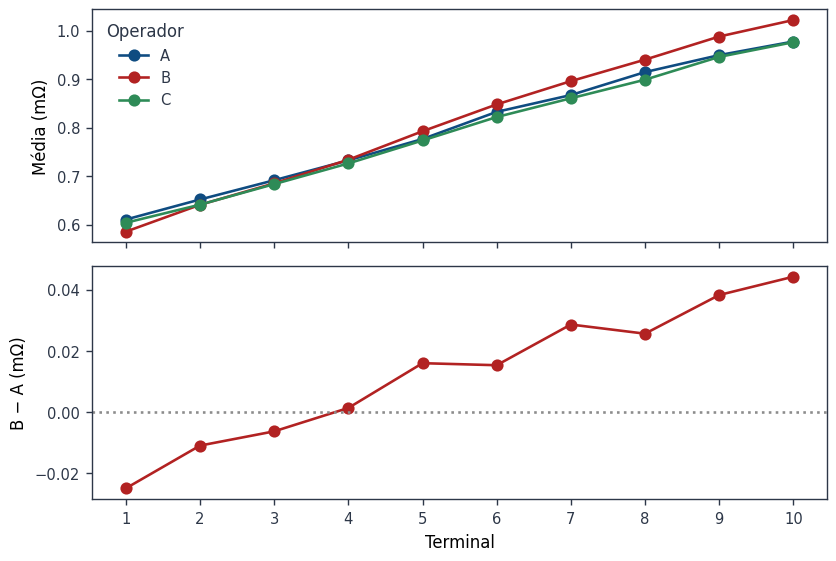

In [21]:
# Cada ponto do perfil é a média das três réplicas do terminal.
# A função desenha os perfis e, abaixo, o contraste B menos A.
figura_interacao = grafico_interacao(terminais)

display(figura_interacao)

## Cap. 12: tendência e estabilidade

In [22]:
# Use os padrões da coleta de linearidade, distintos dos terminais.
tendencias_res, ajuste_res = ajustar_tendencia(
    referencias_mohm, leituras_lineares
)
print("Tendências por referência (mΩ):")
print(", ".join(f"{valor:+.5f}" for valor in tendencias_res))
print(f"Inclinação: {ajuste_res.slope:.5f} mΩ/mΩ")

# Congele os limites de controle estimados nos 20 primeiros dias.
(
    medias_res, amplitudes_res, limites_x_res, limites_r_res,
    sinais_x_res, sinais_r_res,
) = carta_medias_amplitudes(leituras_diarias, 20, constantes_carta)
print(f"Carta de médias: [{limites_x_res[0]:.5f}, "
      f"{limites_x_res[1]:.5f}] mΩ")
print(f"Dias sinalizados na carta de médias: {sinais_x_res.tolist()}")
print(f"Carta R: [{limites_r_res[0]:.5f}, "
      f"{limites_r_res[1]:.5f}] mΩ")
print(f"Dias sinalizados na carta R: {sinais_r_res.tolist()}")

Tendências por referência (mΩ):
-0.00700, -0.00167, +0.00317, +0.00833, +0.01433
Inclinação: 0.05267 mΩ/mΩ
Carta de médias: [0.79938, 0.80862] mΩ
Dias sinalizados na carta de médias: [23]
Carta R: [0.00000, 0.01691] mΩ
Dias sinalizados na carta R: []


## Cap. 12: gráfico da estabilidade elétrica

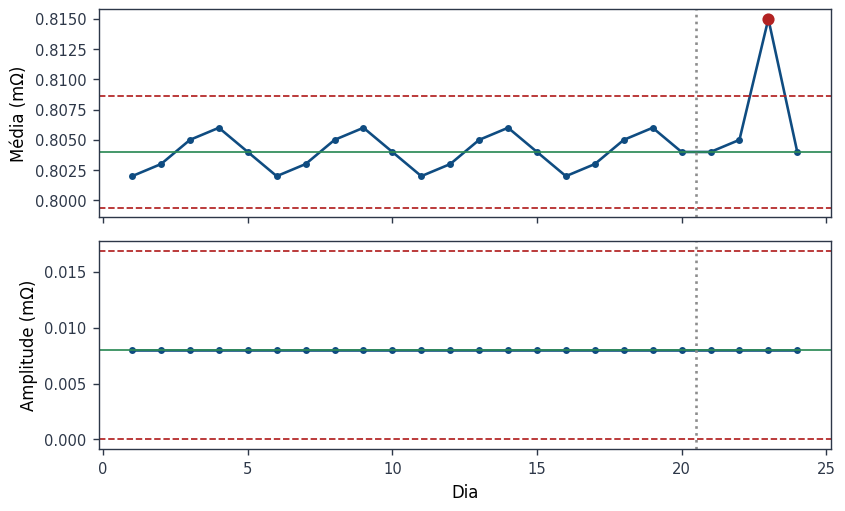

In [23]:
# Reuse a função das cartas com as médias, amplitudes e limites em mΩ.
figura_estabilidade_res = grafico_estabilidade(
    medias_res, amplitudes_res, limites_x_res, limites_r_res,
    sinais_x_res, sinais_r_res, dias_fase1=20, unidade="mΩ"
)

display(figura_estabilidade_res)

## Cap. 13: acerto frente à referência

In [24]:
# Cada rodada tem uma decisão por terminal. Não misture as rodadas.
# enumerate() fornece o índice e o nome de cada avaliador.
for indice, avaliador in enumerate("ABC"):
    for rodada in range(2):
        # Selecione todos os terminais para este avaliador e rodada.
        decisoes = DECISOES_CRIMPAGEM[:, indice, rodada]
        matriz = matriz_classificacao(REFERENCIA_CRIMPAGEM, decisoes)
        acertos = matriz.trace()  # Soma da diagonal principal.
        print(f"{avaliador}/{rodada + 1}: {acertos}/24 acertos, "
              f"{matriz[0, 1]}/12 fugas, {matriz[1, 0]}/12 falsos alarmes, "
              f"κ={kappa_cohen(matriz):.3f}")

A/1: 23/24 acertos, 1/12 fugas, 0/12 falsos alarmes, κ=0.917
A/2: 22/24 acertos, 1/12 fugas, 1/12 falsos alarmes, κ=0.833
B/1: 21/24 acertos, 3/12 fugas, 0/12 falsos alarmes, κ=0.750
B/2: 21/24 acertos, 3/12 fugas, 0/12 falsos alarmes, κ=0.750
C/1: 23/24 acertos, 0/12 fugas, 1/12 falsos alarmes, κ=0.917
C/2: 22/24 acertos, 0/12 fugas, 2/12 falsos alarmes, κ=0.833


## Cap. 13: gráfico das matrizes

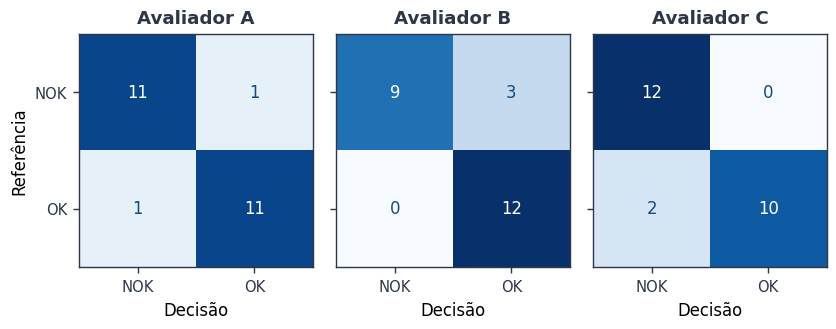

In [25]:
# O índice 1 seleciona a segunda rodada para os três avaliadores.
# A função colore as contagens de cada matriz usando imshow().
figura_crimpagem = grafico_crimpagem(
    REFERENCIA_CRIMPAGEM, DECISOES_CRIMPAGEM[:, :, 1]
)

display(figura_crimpagem)

## Cap. 13: consistência e concordância

In [26]:
# enumerate() fornece o índice e o nome de cada avaliador.
for indice, avaliador in enumerate("ABC"):
    # Compare a mesma peça nas duas rodadas do mesmo avaliador.
    primeira, segunda = DECISOES_CRIMPAGEM[:, indice, :].T
    # count_nonzero() conta quantas comparações são verdadeiras.
    repetidas = np.count_nonzero(primeira == segunda)
    kappa_intra = kappa_cohen(matriz_classificacao(primeira, segunda))
    print(f"{avaliador}: {repetidas}/24 consistentes, κ={kappa_intra:.3f}")

for rodada in range(2):
    # Quando máximo e mínimo coincidem, todos votaram igual.
    votos = DECISOES_CRIMPAGEM[:, :, rodada]
    unanimes = np.count_nonzero(np.ptp(votos, axis=1) == 0)
    kappa_entre = kappa_fleiss(votos)
    print(f"Rodada {rodada + 1}: {unanimes}/24 unânimes, "
          f"κ de Fleiss={kappa_entre:.3f}")

A: 23/24 consistentes, κ=0.917
B: 22/24 consistentes, κ=0.822
C: 23/24 consistentes, κ=0.915
Rodada 1: 20/24 unânimes, κ de Fleiss=0.776
Rodada 2: 19/24 unânimes, κ de Fleiss=0.722
